In [1]:
import sys
# sys.path.insert(0, '../../Utilities/')

# from jax.example_libraries import optimizers
import jax.numpy as jnp
import numpy as np
from jax import grad, jit, vmap, value_and_grad, hessian
from jax import random
from functools import partial
import flax.linen as nn
import jax
import optax
import pickle
from datetime import datetime
import os
import numpy as np
from scipy import sparse
import time
from jax import grad, hessian, jit, vmap, pmap
from jax.tree_util import tree_leaves
from datetime import datetime
import matplotlib.pyplot as plt
import pickle
import flax.linen as nn
import optax
import optax.tree_utils as otu

from mg_pinn_class import MinMaxOptProb

In [6]:
# Define boundary and initial conditions
def u0(x):
    # return 2*smooth_sign(x) - 1
    return -jnp.sin(jnp.pi * x)
    # return -jnp.sin(jnp.pi*x)
# def u_exact(tx):
#     t, x = tx[0], tx[1]
#     return u0(x-0.5*t)
# vec_u_exact = vmap(u_exact)

# Boundary at x=-1
def u1(x):
    return 0

# Boundary at x=1
def u2(x):
    return 0


def res_visc(u_quad, u_t, u_x, u_xx, nu, u_exact=0):
    # print(f"u_quad shape: {u_quad.shape}")
    # print(f"u2_x shape: {u2_x.shape}")
    # print(f"u_xx shape: {u_xx.shape}")
    return u_t + u_quad*u_x - nu*u_xx
    # return u_t + 0.8*u_x - nu*u_xx
    # return jnp.zeros_like(u_quad)
    # return u_quad - u_exact

def res(u_quad, u_t, u_x):
    return u_t + u_quad * u_x
    # return u_t + 0.8*u_x

# Initialize separate loss history lists for each stage
pre_loss_int_history = []
pre_loss_bc_history = []
train_loss_int_history = []
train_loss_bc_history = []

# Initialize the optimization problem
optProb = MinMaxOptProb(
    N_t=16,
    N_x=32,
    lr_theta=1e-3,
    N_bc=100,
    N_ic=200,
    t_min=0, t_max=1, x_min=-1, x_max=1,
    hidden_dims_list=[(40, 40), (40, 40), (40, 40), (40, 40)],
    init_lrs=[1e-3, 1e-3, 1e-3, 1e-3], grade_epochs=[10000, 10000, 10000, 10000], decay_rates=[1e-3, 1e-3, 1e-3, 1e-3], init_lr_stage2=1e-3, epoch_stage2=10000, decay_rate_stage2=1e-3,
    seed=0,
    u0=u0, u1=u1, u2=u2,
    nu=0.01,
    res_visc=res_visc,
    res=res,    
)

In [7]:
optProb.pre_train_process()


Starting Pre-Train Stage with MGDL


grade_0_loss_eqn,█▅▄▄▄▃▃▃▂▃▂▂▂▁▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_0_loss_ibc,█▆▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▁▁▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▄▄▅▅▅▅▅▅▅▆▆▆▆▆▇▇▇▇██
grade_0_loss_eqn,0.00192
grade_0_loss_ibc,6e-05
step,10800



Training Grade 0
Grade 0, Epoch 0, lambda_ic: 1.94635367, lambda_bc: 2.12740064, lambda_r: 1.02151299
Grade 0, Epoch 0, loss: 1.00612390, loss_eqn: 0.44993600, loss_ibc: 0.55618793
Grade 0, Epoch 100, loss: 0.42491376, loss_eqn: 0.01286750, loss_ibc: 0.41204628
Grade 0, Epoch 200, loss: 0.22055510, loss_eqn: 0.12976804, loss_ibc: 0.09078705
Grade 0, Epoch 300, loss: 0.18081202, loss_eqn: 0.10330357, loss_ibc: 0.07750845
Grade 0, Epoch 400, loss: 0.13909765, loss_eqn: 0.08142172, loss_ibc: 0.05767592
Grade 0, Epoch 500, loss: 0.11375630, loss_eqn: 0.06746082, loss_ibc: 0.04629548
Grade 0, Epoch 600, loss: 0.09002179, loss_eqn: 0.05485383, loss_ibc: 0.03516796
Grade 0, Epoch 700, loss: 0.05691598, loss_eqn: 0.03394660, loss_ibc: 0.02296938
Grade 0, Epoch 800, loss: 0.03766450, loss_eqn: 0.02011698, loss_ibc: 0.01754751
Grade 0, Epoch 900, loss: 0.03241330, loss_eqn: 0.01835174, loss_ibc: 0.01406156
Grade 0, Epoch 1000, lambda_ic: 2.38697529, lambda_bc: 5.22154474, lambda_r: 1.04246235
G

grade_0_loss_eqn,█▁▃▃▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_0_loss_ibc,█▆▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_1_loss_eqn,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_1_loss_ibc,█▆▅▅▄▃▃▃▂▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_2_loss_eqn,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
grade_2_loss_ibc,█▃▂▂▂▂▂▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
second_stage_loss,█▅▆▆▆▆▇▆▆▇▆▆▆▆▆▆▆▆▅▅▅▅▄▄▄▄▄▄▃▃▃▃▃▂▂▂▂▂▁▁
second_stage_loss_ibc,█▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁▁
step,▁▁▁▂▂▂▂▂▂▂▃▃▃▃▃▃▃▄▄▄▅▅▅▅▅▅▆▆▆▆▆▆▆▆▇▇▇▇▇█
grade_0_loss_eqn,0.00251
grade_0_loss_ibc,0.00076


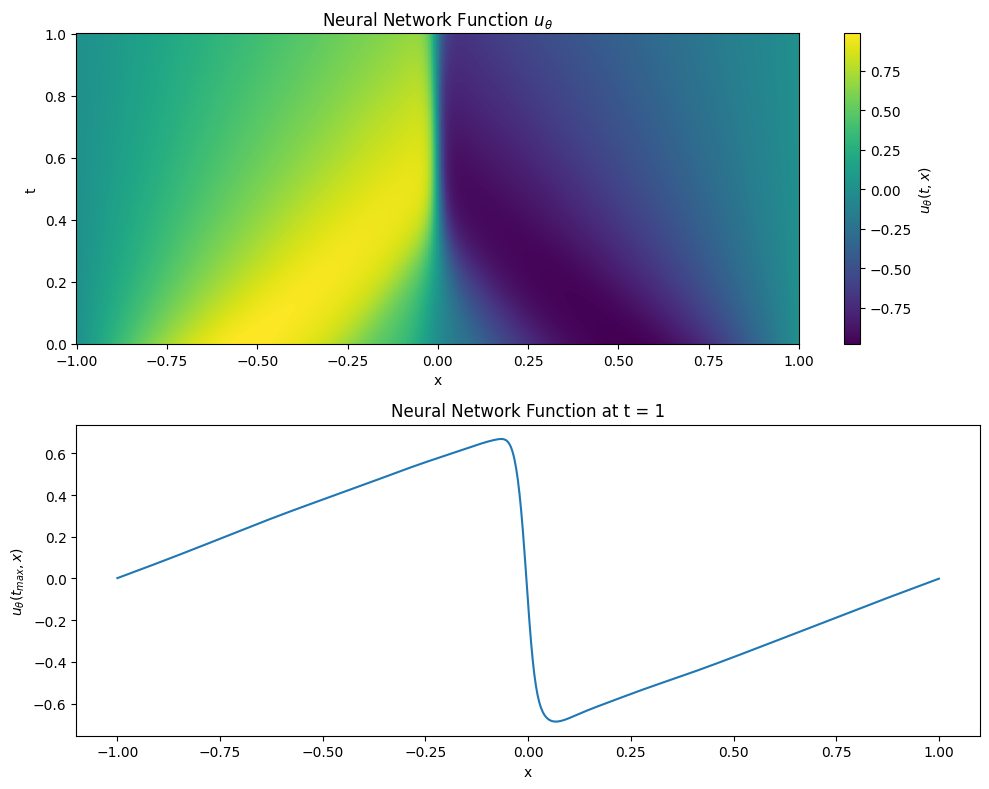

In [8]:
from my_helpers import plot_u_theta
plot_u_theta(optProb.model, M_t=500, M_x=1000, t_min=0.0, t_max=1, x_min=-1.0, x_max=1.0)  # Plot initial model state


In [32]:
%timeit u_eval(X)

3.83 ms ± 380 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [25]:
%timeit optProb.model.forward(X).squeeze()

16.4 ms ± 160 μs per loop (mean ± std. dev. of 7 runs, 100 loops each)


In [26]:
jnp.linalg.norm(optProb.model.forward(X).squeeze()-u_eval(X))

Array(3.177896e-06, dtype=float32)

In [35]:
optProb.params_list = []
for i in range(optProb.total_grade):
    optProb.params_list.append(optProb.model.mlps[i].params)

In [43]:
jnp.linalg.norm(optProb.model.forward(X).squeeze()-optProb.model.forward_with_params(optProb.params_list, X).squeeze())

Array(0., dtype=float32)